In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ulrikthygepedersen/fastfood-nutrition/fastfood.csv


In [2]:
df = pd.read_csv("/kaggle/input/datasets/ulrikthygepedersen/fastfood-nutrition/fastfood.csv")
df.head()

,restaurant,item,calories,cal_fat,total_fat,sat_fat,trans_fat,cholesterol,sodium,total_carb,fiber,sugar,protein,vit_a,vit_c,calcium,salad
0,Mcdonalds,Artisan Grilled Chicken Sandwich,380,60,7,2.0,0.0,95,1110,44,3.0,11,37.0,4.0,20.0,20.0,Other
1,Mcdonalds,Single Bacon Smokehouse Burger,840,410,45,17.0,1.5,130,1580,62,2.0,18,46.0,6.0,20.0,20.0,Other
2,Mcdonalds,Double Bacon Smokehouse Burger,1130,600,67,27.0,3.0,220,1920,63,3.0,18,70.0,10.0,20.0,50.0,Other
3,Mcdonalds,Grilled Bacon Smokehouse Chicken Sandwich,750,280,31,10.0,0.5,155,1940,62,2.0,18,55.0,6.0,25.0,20.0,Other
4,Mcdonalds,Crispy Bacon Smokehouse Chicken Sandwich,920,410,45,12.0,0.5,120,1980,81,4.0,18,46.0,6.0,20.0,20.0,Other


`Read the dataset`

In [3]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Shape: (515, 17)

Columns:
['restaurant', 'item', 'calories', 'cal_fat', 'total_fat', 'sat_fat', 'trans_fat', 'cholesterol', 'sodium', 'total_carb', 'fiber', 'sugar', 'protein', 'vit_a', 'vit_c', 'calcium', 'salad']


In [4]:
print("\nData types:")
print(df.dtypes)


Data types:
restaurant      object
item            object
calories         int64
cal_fat          int64
total_fat        int64
sat_fat        float64
trans_fat      float64
cholesterol      int64
sodium           int64
total_carb       int64
fiber          float64
sugar            int64
protein        float64
vit_a          float64
vit_c          float64
calcium        float64
salad           object
dtype: object


In [5]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
restaurant       0
item             0
calories         0
cal_fat          0
total_fat        0
sat_fat          0
trans_fat        0
cholesterol      0
sodium           0
total_carb       0
fiber           12
sugar            0
protein          1
vit_a          214
vit_c          210
calcium        210
salad            0
dtype: int64


In [6]:
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 2


In [7]:
print("\nRestaurants:")
print(df['restaurant'].value_counts())


Restaurants:
restaurant
Taco Bell      115
Subway          96
Burger King     70
Mcdonalds       57
Arbys           55
Sonic           53
Dairy Queen     42
Chick Fil-A     27
Name: count, dtype: int64


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
calories,515.0,530.912621,282.436147,20.0,330.0,490.0,690.0,2430.0
cal_fat,515.0,238.813592,166.407510,0.0,120.0,210.0,310.0,1270.0
total_fat,515.0,26.590291,18.411876,0.0,14.0,23.0,35.0,141.0
sat_fat,515.0,8.153398,6.418811,0.0,4.0,7.0,11.0,47.0
trans_fat,515.0,0.465049,0.839644,0.0,0.0,0.0,1.0,8.0
cholesterol,515.0,72.456311,63.160406,0.0,35.0,60.0,95.0,805.0
sodium,515.0,1246.737864,689.954278,15.0,800.0,1110.0,1550.0,6080.0
total_carb,515.0,45.664078,24.883342,0.0,28.5,44.0,57.0,156.0
fiber,503.0,4.137177,3.037460,0.0,2.0,3.0,5.0,17.0
sugar,515.0,7.262136,6.761301,0.0,3.0,6.0,9.0,87.0


`Data Preprocessing`
1. Remove exact duplicate rows.
2. Clean text columns by removing unnecessary leading/trailing spaces.
3. Convert nutritional columns to numeric.
4. Fill missing numeric values using the median.
5. Check the salad category.

In [9]:
#copy df
clean_df = df.copy()
clean_df = clean_df.drop_duplicates().reset_index(drop=True)

In [10]:
clean_df.shape

(513, 17)

In [11]:
# Clean text columns
for col in ['restaurant', 'item', 'salad']:
    clean_df[col] = clean_df[col].astype(str).str.strip()

In [12]:
# Numeric columns
numeric_cols = [
    'calories', 'cal_fat', 'total_fat', 'sat_fat', 'trans_fat',
    'cholesterol', 'sodium', 'total_carb', 'fiber', 'sugar',
    'protein', 'vit_a', 'vit_c', 'calcium'
]


In [13]:
for col in numeric_cols:
    clean_df[col] = pd.to_numeric(clean_df[col], errors='coerce')


In [14]:
# Missing-value handle
for col in numeric_cols:
    clean_df[col] = clean_df[col].fillna(clean_df[col].median())


In [15]:
print("Original shape:", df.shape)
print("After removing duplicates:", clean_df.shape)

print("\nRemaining missing values:")
print(clean_df.isnull().sum())

print("\nFood type distribution:")
print(clean_df['salad'].value_counts())

Original shape: (515, 17)
After removing duplicates: (513, 17)

Remaining missing values:
restaurant     0
item           0
calories       0
cal_fat        0
total_fat      0
sat_fat        0
trans_fat      0
cholesterol    0
sodium         0
total_carb     0
fiber          0
sugar          0
protein        0
vit_a          0
vit_c          0
calcium        0
salad          0
dtype: int64

Food type distribution:
salad
Other    513
Name: count, dtype: int64


`Duplicate Stats`

In [16]:
clean_df.describe().T

,count,mean,std,min,25%,50%,75%,max
calories,513.0,531.111111,282.900251,20.0,330.0,490.0,690.0,2430.0
cal_fat,513.0,238.945419,166.683320,0.0,120.0,210.0,310.0,1270.0
total_fat,513.0,26.604288,18.442620,0.0,14.0,23.0,35.0,141.0
sat_fat,513.0,8.152047,6.431223,0.0,4.0,7.0,11.0,47.0
trans_fat,513.0,0.462963,0.840615,0.0,0.0,0.0,1.0,8.0
cholesterol,513.0,72.553606,63.259522,0.0,35.0,60.0,95.0,805.0
sodium,513.0,1247.309942,691.157795,15.0,800.0,1110.0,1550.0,6080.0
total_carb,513.0,45.647173,24.924070,0.0,28.0,44.0,57.0,156.0
fiber,513.0,4.101365,3.007390,0.0,2.0,3.0,5.0,17.0
sugar,513.0,7.272904,6.770483,0.0,3.0,6.0,9.0,87.0


`EDA`

In [17]:
import matplotlib.pyplot as plt

`Question 1: Which restaurant has the highest number of food items?`

restaurant
Taco Bell      113
Subway          96
Burger King     70
Mcdonalds       57
Arbys           55
Sonic           53
Dairy Queen     42
Chick Fil-A     27
Name: item, dtype: int64

Answer: Taco Bell has the highest number of food items (113).


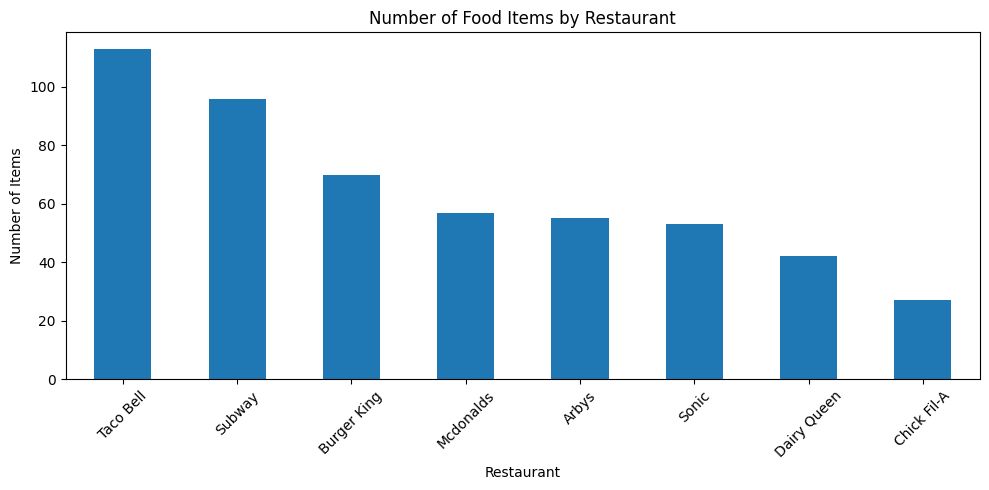

In [18]:
restaurant_item_count = (
    clean_df.groupby('restaurant')['item']
    .count()
    .sort_values(ascending=False)
)

print(restaurant_item_count)

highest_restaurant = restaurant_item_count.idxmax()
highest_count = restaurant_item_count.max()

print(f"\nAnswer: {highest_restaurant} has the highest number of food items ({highest_count}).")

plt.figure(figsize=(10, 5))
restaurant_item_count.plot(kind='bar')
plt.title('Number of Food Items by Restaurant')
plt.xlabel('Restaurant')
plt.ylabel('Number of Items')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


`Question 2: Which food items have the highest number of calories? Top 10`

In [19]:
top10_calories = (
    clean_df[['restaurant', 'item', 'calories']]
    .sort_values('calories', ascending=False)
    .head(10)
    .reset_index(drop=True)
)

top10_calories


,restaurant,item,calories
0,Mcdonalds,20 piece Buttermilk Crispy Chicken Tenders,2430
1,Mcdonalds,40 piece Chicken McNuggets,1770
2,Mcdonalds,10 piece Sweet N' Spicy Honey BBQ Glazed Tenders,1600
3,Burger King,American Brewhouse King,1550
4,Mcdonalds,12 piece Buttermilk Crispy Chicken Tenders,1510
5,Sonic,Garlic Parmesan Dunked Ultimate Chicken Sandwich,1350
6,Sonic,Super Sonic Bacon Double Cheeseburger (w/mayo),1280
7,Dairy Queen,6 Piece Chicken Strip Basket w/ Country Gravy,1260
8,Burger King,Rodeo King,1250
9,Sonic,Super Sonic Double Cheeseburger W/ Mayo,1220


`Question 3: What is the average calorie count of food items for each restaurant?`

restaurant
Mcdonalds      640.35
Sonic          631.70
Burger King    608.57
Arbys          532.73
Dairy Queen    520.24
Subway         503.02
Taco Bell      443.01
Chick Fil-A    384.44
Name: calories, dtype: float64


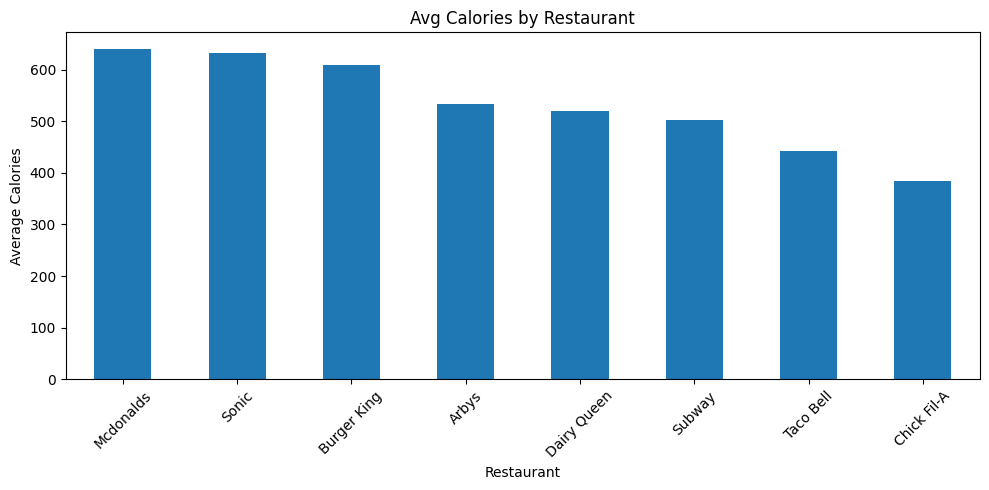

In [20]:
avg_calories = (
    clean_df.groupby('restaurant')['calories']
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print(avg_calories)

plt.figure(figsize=(10, 5))
avg_calories.plot(kind='bar')
plt.title('Avg Calories by Restaurant')
plt.xlabel('Restaurant')
plt.ylabel('Average Calories')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


`Question 4: Which restaurant offers food items with the highest average protein content?`


In [21]:
avg_protein = (
    clean_df.groupby('restaurant')['protein']
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print(avg_protein)

print(
    f"\nAnswer: {avg_protein.idxmax()} has the highest average protein "
    f"content ({avg_protein.max():.2f} g)."
)


restaurant
Mcdonalds      40.30
Chick Fil-A    31.70
Subway         30.31
Burger King    29.94
Arbys          29.25
Sonic          29.19
Dairy Queen    24.83
Taco Bell      17.38
Name: protein, dtype: float64

Answer: Mcdonalds has the highest average protein content (40.30 g).


`Question 5: Which restaurant has the highest and lowest average total fat?`

In [22]:
avg_fat = (
    clean_df.groupby('restaurant')['total_fat']
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print(avg_fat)

print(f"\nHighest average total fat: {avg_fat.idxmax()} ({avg_fat.max():.2f} g)")
print(f"Lowest average total fat: {avg_fat.idxmin()} ({avg_fat.min():.2f} g)")


restaurant
Sonic          37.64
Burger King    36.81
Mcdonalds      31.81
Dairy Queen    28.86
Arbys          26.98
Taco Bell      20.86
Subway         18.48
Chick Fil-A    16.15
Name: total_fat, dtype: float64

Highest average total fat: Sonic (37.64 g)
Lowest average total fat: Chick Fil-A (16.15 g)


`Question 6: Which food items contain the highest amount of sugar, and how many calories do they contain?`

Show the top 10 highest-sugar items.


In [23]:
top10_sugar = (
    clean_df[['restaurant', 'item', 'sugar', 'calories']]
    .sort_values('sugar', ascending=False)
    .head(10)
    .reset_index(drop=True)
)

top10_sugar


,restaurant,item,sugar,calories
0,Mcdonalds,10 piece Sweet N' Spicy Honey BBQ Glazed Tenders,87,1600
1,Mcdonalds,6 piece Sweet N' Spicy Honey BBQ Glazed Tenders,52,960
2,Burger King,"Chicken, Apple & Cranberry Salad w/ Crispy Chi...",37,700
3,Subway,Footlong Sweet Onion Chicken Teriyaki,36,760
4,Mcdonalds,4 piece Sweet N' Spicy Honey BBQ Glazed Tenders,35,640
5,Burger King,"Chicken, Apple & Cranberry Salad w/ Grilled Ch...",34,560
6,Dairy Queen,Large Cheese Curds,30,1050
7,Subway,Footlong Corned Beef Reuben,24,940
8,Subway,Footlong Meatball Marinara,24,960
9,Arbys,Arby-Q Sandwich,23,400


`Question 7: How does the food type (salad or other) affect average calories, fat, carbohydrates and protein?`

First inspect the category values. If only one category exists, a Salad-vs-Other comparison is not statistically possible from this dataset.


In [24]:
print(clean_df['salad'].value_counts())

food_type_summary = clean_df.groupby('salad')[
    ['calories', 'total_fat', 'total_carb', 'protein']
].mean().round(2)

print(food_type_summary)

if clean_df['salad'].nunique() < 2:
    print("Question 7 cannot be compared because the dataset contains only one food type category.")
else:
    print(food_type_summary)

    food_type_summary.plot(kind='bar', figsize=(10, 5))
    plt.title('Average Nutrition by Food Type')
    plt.ylabel('Average Amount')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


salad
Other    513
Name: count, dtype: int64
       calories  total_fat  total_carb  protein
salad                                          
Other    531.11       26.6       45.65    27.92
Question 7 cannot be compared because the dataset contains only one food type category.


`Question 8: Which restaurant offers the best combination of low calories and high protein?`

A simple scoring system is used:
- Lower average calories = better
- Higher average protein = better
- Both components receive equal weight (50% each)

The two values are min-max normalized across restaurants.


In [25]:
restaurant_summary = clean_df.groupby('restaurant').agg(
    avg_calories=('calories', 'mean'),
    avg_protein=('protein', 'mean')
)

# Lower calories should receive a higher score
restaurant_summary['low_calorie_score'] = (
    1 - (
        (restaurant_summary['avg_calories'] - restaurant_summary['avg_calories'].min()) /
        (restaurant_summary['avg_calories'].max() - restaurant_summary['avg_calories'].min())
    )
)

# Higher protein should receive a higher score
restaurant_summary['high_protein_score'] = (
    (restaurant_summary['avg_protein'] - restaurant_summary['avg_protein'].min()) /
    (restaurant_summary['avg_protein'].max() - restaurant_summary['avg_protein'].min())
)

restaurant_summary['protein_calorie_score'] = (
    (restaurant_summary['low_calorie_score'] +
     restaurant_summary['high_protein_score']) / 2 * 100
)

restaurant_summary = restaurant_summary.sort_values(
    'protein_calorie_score', ascending=False
).round(2)

restaurant_summary


,avg_calories,avg_protein,low_calorie_score,high_protein_score,protein_calorie_score
restaurant,,,,,
Chick Fil-A,384.44,31.70,1.00,0.62,81.25
Subway,503.02,30.31,0.54,0.56,55.05
Mcdonalds,640.35,40.30,0.00,1.00,50.00
Arbys,532.73,29.25,0.42,0.52,46.93
Dairy Queen,520.24,24.83,0.47,0.33,39.73
Taco Bell,443.01,17.38,0.77,0.00,38.56
Burger King,608.57,29.94,0.12,0.55,33.62
Sonic,631.70,29.19,0.03,0.52,27.45


`Question 9: Identify the 10 least healthy food items using a Health Risk Score`

Risk factors:
- Calories
- Total fat
- Saturated fat
- Trans fat
- Cholesterol
- Sodium

For each variable, min-max normalization converts the value to 0–1. All six risk factors receive equal weight.

`Higher Health Risk Score = less healthy.`


In [26]:
risk_cols = [
    'calories', 'total_fat', 'sat_fat',
    'trans_fat', 'cholesterol', 'sodium'
]

risk_normalized = (
    clean_df[risk_cols] - clean_df[risk_cols].min()
) / (
    clean_df[risk_cols].max() - clean_df[risk_cols].min()
)

clean_df['health_risk_score'] = risk_normalized.mean(axis=1) * 100

top10_risk = (
    clean_df[['restaurant', 'item'] + risk_cols + ['health_risk_score']]
    .sort_values('health_risk_score', ascending=False)
    .head(10)
    .reset_index(drop=True)
)

top10_risk.round(2)


,restaurant,item,calories,total_fat,sat_fat,trans_fat,cholesterol,sodium,health_risk_score
0,Burger King,American Brewhouse King,1550,126,47.0,8.0,805,1820,80.43
1,Mcdonalds,20 piece Buttermilk Crispy Chicken Tenders,2430,141,24.0,2.0,475,6080,72.51
2,Sonic,Super Sonic Bacon Double Cheeseburger (w/mayo),1280,92,36.0,4.0,260,1630,50.51
3,Sonic,Super Sonic Double Cheeseburger W/ Mayo,1220,87,34.0,4.0,245,1520,48.18
4,Mcdonalds,40 piece Chicken McNuggets,1770,107,18.0,0.5,295,3370,47.50
5,Burger King,Rodeo King,1250,82,31.0,3.5,230,2270,47.44
6,Burger King,Farmhouse King,1220,80,28.0,3.0,335,2050,46.46
7,Sonic,Super Sonic Jalapeno Double Cheeseburger,1120,76,32.0,4.0,235,1690,45.74
8,Sonic,Super Sonic Double Cheeseburger W/ Ketchup,1130,76,32.0,4.0,235,1620,45.62
9,Sonic,Super Sonic Double Cheeseburger W/ Mustard,1120,76,32.0,4.0,235,1550,45.36


`Question 10: Compare all restaurants and determine the healthiest overall menu`

### Scoring system

Negative factors:
- Lower calories → higher score
- Lower total fat → higher score
- Lower sugar → higher score
- Lower sodium → higher score

Positive factors:
- Higher fiber → higher score
- Higher protein → higher score
- Higher vitamin/mineral score → higher score

Vitamin/mineral score is the average normalized value of:
- Vitamin A
- Vitamin C
- Calcium

All seven components receive equal weight.

`Overall score = average of the seven component scores × 100.`

**Explanation:** Because the dataset has substantial missing values for Vitamin A, Vitamin C and Calcium, the preprocessing step uses median imputation. Therefore, the ranking should be interpreted as a comparative score for this dataset, not a medical judgment.


In [27]:
def minmax(series):
    return (series - series.min()) / (series.max() - series.min())

# Positive health scores
clean_df['score_calories'] = 1 - minmax(clean_df['calories'])
clean_df['score_fat'] = 1 - minmax(clean_df['total_fat'])
clean_df['score_sugar'] = 1 - minmax(clean_df['sugar'])
clean_df['score_sodium'] = 1 - minmax(clean_df['sodium'])

clean_df['score_fiber'] = minmax(clean_df['fiber'])
clean_df['score_protein'] = minmax(clean_df['protein'])

vit_a_score = minmax(clean_df['vit_a'])
vit_c_score = minmax(clean_df['vit_c'])
calcium_score = minmax(clean_df['calcium'])

clean_df['score_vitamins'] = (
    vit_a_score + vit_c_score + calcium_score
) / 3

score_cols = [
    'score_calories', 'score_fat', 'score_sugar',
    'score_sodium', 'score_fiber', 'score_protein',
    'score_vitamins'
]

clean_df['overall_health_score'] = (
    clean_df[score_cols].mean(axis=1) * 100
)

restaurant_health = (
    clean_df.groupby('restaurant')
    .agg(
        overall_health_score=('overall_health_score', 'mean'),
        avg_calories=('calories', 'mean'),
        avg_fat=('total_fat', 'mean'),
        avg_sugar=('sugar', 'mean'),
        avg_sodium=('sodium', 'mean'),
        avg_fiber=('fiber', 'mean'),
        avg_protein=('protein', 'mean'),
        avg_vit_a=('vit_a', 'mean'),
        avg_vit_c=('vit_c', 'mean'),
        avg_calcium=('calcium', 'mean')
    )
    .sort_values('overall_health_score', ascending=False)
    .round(2)
)

restaurant_health


,overall_health_score,avg_calories,avg_fat,avg_sugar,avg_sodium,avg_fiber,avg_protein,avg_vit_a,avg_vit_c,avg_calcium
restaurant,,,,,,,,,,
Subway,57.30,503.02,18.48,10.09,1272.97,6.56,30.31,22.39,41.97,39.12
Taco Bell,56.35,443.01,20.86,3.69,1012.39,5.70,17.38,10.42,8.74,21.11
Chick Fil-A,55.03,384.44,16.15,4.15,1151.48,2.37,31.70,12.04,13.78,11.96
Dairy Queen,52.38,520.24,28.86,6.36,1181.79,2.83,24.83,12.57,6.38,17.69
Mcdonalds,52.27,640.35,31.81,11.07,1437.89,3.23,40.30,33.72,18.30,20.60
Arbys,51.77,532.73,26.98,7.56,1515.27,2.71,29.25,11.16,9.27,18.80
Burger King,50.76,608.57,36.81,8.19,1223.57,2.47,29.94,10.00,10.00,20.00
Sonic,50.45,631.70,37.64,6.53,1350.75,2.66,29.19,7.17,6.08,17.45


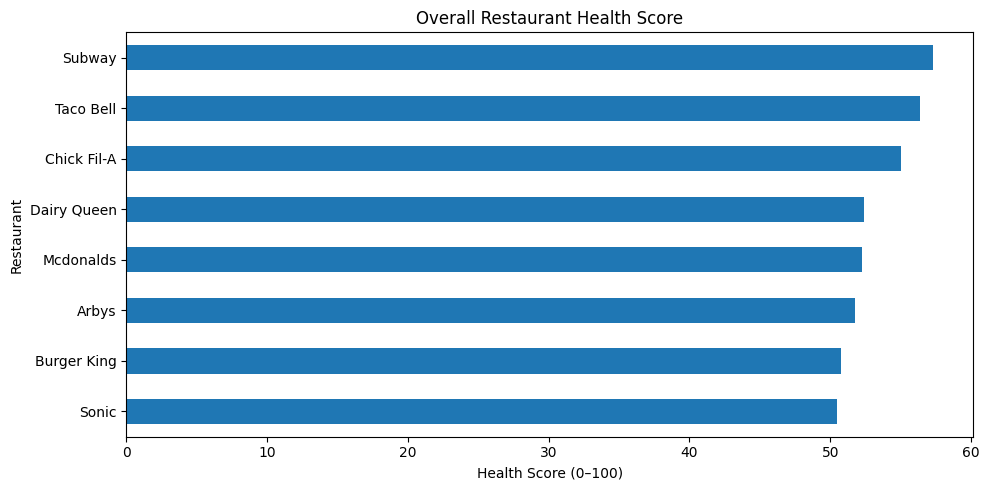

Healthiest overall menu by this scoring system: Subway (57.30/100)


In [28]:
# Visualize final restaurant ranking
plt.figure(figsize=(10, 5))
restaurant_health['overall_health_score'].sort_values().plot(kind='barh')
plt.title('Overall Restaurant Health Score')
plt.xlabel('Health Score (0–100)')
plt.ylabel('Restaurant')
plt.tight_layout()
plt.show()

print(
    f"Healthiest overall menu by this scoring system: "
    f"{restaurant_health.index[0]} "
    f"({restaurant_health.iloc[0]['overall_health_score']:.2f}/100)"
)
